# 01: a dense-network baseline on the artworks (milestone m1)

WikiArt subset: 5 genres (cityscape, landscape, portrait, religious_painting, still_life), 300 images per
genre, 128 x 128 pixels. Built with `make_wikiart_subset.py` (exact command in the README).

## Imports

- `torch`, `torch.nn`, `torch.utils.data`: PyTorch, as in Session 4.
- `torchvision.datasets`: `ImageFolder` reads the subset (one folder per genre).
- `sklearn.metrics.confusion_matrix`: counts, for each true class, how often each class was predicted.
- `pandas`: reads `metadata.csv` (the artist of each image).
- `numpy`, `matplotlib`: arrays and plots.

In [1]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
from sklearn.metrics import confusion_matrix

DATA_DIR = "data/wikiart_genre5"
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(2)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## Helper functions

`evaluate`, `train_one_epoch` and `fit` are the functions of TP04, as given at the top of TP05 (the clean training
loop of Session 4). `fit` returns a dictionary with one value per epoch for `"train_loss"`, `"val_loss"` and
`"val_acc"`.

In [2]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return total_loss / total, correct / total


def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    running, total = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(yb)
        total += len(yb)
    return running / total


def fit(model, train_loader, val_loader, loss_fn, optimizer, n_epochs, verbose=True):
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(n_epochs):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if verbose:
            print(f"epoch {epoch + 1:2d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.3f}")
    return history

## Load the images

`datasets.ImageFolder(DATA_DIR)` reads the subset: one folder per genre, class indices in alphabetical order of the
folder names. As in TP05, we do not keep the image-by-image interface: we read the 1 500 images once and stack them
in one tensor `X_full` of shape `(N, 3, 128, 128)` (channels first, as PyTorch expects), with pixels in $[0, 1]$, and
the labels in `y_full`, an `int64` tensor of shape `(N,)`.

X_full (1500, 3, 128, 128) torch.float32 | y_full (1500,) torch.int64
images per class: {'cityscape': 300, 'landscape': 300, 'portrait': 300, 'religious_painting': 300, 'still_life': 300}


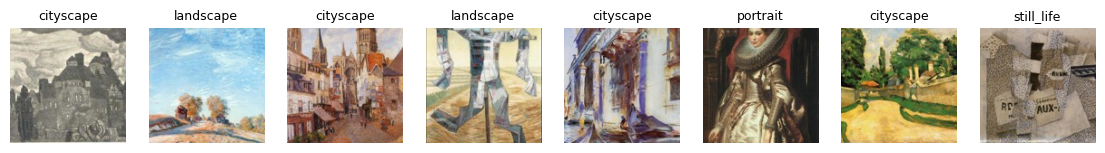

In [3]:
folder = datasets.ImageFolder(DATA_DIR)
CLASSES = folder.classes
images = np.stack([np.array(img) for img, _ in folder])          # (N, 128, 128, 3), uint8, values 0 to 255
X_full = torch.tensor(images).permute(0, 3, 1, 2).float() / 255  # (N, 3, 128, 128), pixels in [0, 1]
y_full = torch.tensor(folder.targets)                             # (N,), int64

print("X_full", tuple(X_full.shape), X_full.dtype, "| y_full", tuple(y_full.shape), y_full.dtype)
print("images per class:", dict(zip(CLASSES, torch.bincount(y_full).tolist())))

show = torch.randperm(len(y_full), generator=torch.Generator().manual_seed(0))[:8]
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
for ax, k in zip(axes, show):
    ax.imshow(X_full[k].permute(1, 2, 0)); ax.set_title(CLASSES[y_full[k]], fontsize=9); ax.axis("off")
plt.show()

## Split train / validation / test, by artist

As in Session 4: train to compute the gradients, validation to choose, test measured once at the end, with a fixed
seed. One more rule from the production checklist of Session 8: **no artist on both sides**. Otherwise the network
can recognise the painter (Monet's brush) instead of the genre, and the test score is optimistic.

So we split **groups**, not images: all the paintings of a named artist go to the same set. "Unknown Artist" is a
catch-all of many painters, so each of its images is its own group. The groups are visited in a random order and a
group goes to test if it fits there (at most 1/6 of each class), else to validation, else to train: 1/6, 1/6 and 2/3
of each class, as with the digits of Session 4.

In [4]:
meta = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv")).set_index("path")
artist = [meta.loc[os.path.relpath(p, DATA_DIR), "artist"] for p, _ in folder.samples]
# one group per named artist; "Unknown Artist" is a catch-all of many painters, so each of its images is its own group
group = [a if a != "Unknown Artist" else f"unknown_{i}" for i, a in enumerate(artist)]
names = sorted(set(group))
members = {g: [i for i, h in enumerate(group) if h == g] for g in names}

# groups in a random order: a group goes to test if it fits there (at most 1/6 of each class), else to validation,
# else to train. Classes stay balanced and an artist never appears in two sets.
order = torch.randperm(len(names), generator=torch.Generator().manual_seed(0)).tolist()
per_class = torch.bincount(y_full) // 6                         # 50 images of each class in test and in validation
filled = {"test": torch.zeros(len(CLASSES), dtype=torch.int64), "val": torch.zeros(len(CLASSES), dtype=torch.int64)}
split = {"train": [], "val": [], "test": []}
for k in order:
    idx = members[names[k]]
    counts = torch.bincount(y_full[idx], minlength=len(CLASSES))
    s = next((s for s in ["test", "val"] if (filled[s] + counts <= per_class).all()), "train")
    if s != "train":
        filled[s] += counts
    split[s] += idx
train_idx, val_idx, test_idx = (torch.tensor(sorted(split[s])) for s in ["train", "val", "test"])

X_train_raw, y_train = X_full[train_idx], y_full[train_idx]
X_val_raw, y_val = X_full[val_idx], y_full[val_idx]
X_test_raw, y_test = X_full[test_idx], y_full[test_idx]

named = {s: {artist[i] for i in split[s]} - {"Unknown Artist"} for s in split}
assert not (named["train"] & named["val"] or named["train"] & named["test"] or named["val"] & named["test"]), "an artist is on both sides"
print(f"train {len(train_idx)}, val {len(val_idx)}, test {len(test_idx)} | no named artist in two sets")
for s, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{s:5s}", dict(zip(CLASSES, torch.bincount(y, minlength=len(CLASSES)).tolist())))

train 1000, val 250, test 250 | no named artist in two sets
train {'cityscape': 200, 'landscape': 200, 'portrait': 200, 'religious_painting': 200, 'still_life': 200}
val   {'cityscape': 50, 'landscape': 50, 'portrait': 50, 'religious_painting': 50, 'still_life': 50}
test  {'cityscape': 50, 'landscape': 50, 'portrait': 50, 'religious_painting': 50, 'still_life': 50}


## Standardise

As in TP05: subtract the mean and divide by the standard deviation, so that the inputs have mean 0 and standard
deviation 1. The two numbers are computed **on the training set only** (over all its pixels) and applied to the three
sets: the validation and test sets must stay "unseen".

In [5]:
mean = X_train_raw.mean().item()   # one number over all the training pixels
std = X_train_raw.std().item()

X_train = (X_train_raw - mean) / std
X_val = (X_val_raw - mean) / std
X_test = (X_test_raw - mean) / std

print(f"mean {mean:.4f}, std {std:.4f} | X_train: mean {X_train.mean().item():.4f}, std {X_train.std().item():.4f}")

mean 0.4546, std 0.2533 | X_train: mean -0.0000, std 1.0000


## The DataLoaders

As in TP05, with the ready-made `TensorDataset(X, y)`: the training loader is shuffled (a new order at each epoch),
validation and test are not. Batch size 64, as in TP06 where the training set is also small (2 000 images): with
1 000 training images that is 16 steps per epoch.

In [6]:
BATCH_SIZE = 64
torch.manual_seed(0)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=1000, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=1000, shuffle=False)

xb, yb = next(iter(train_loader))
print("one batch:", tuple(xb.shape), tuple(yb.shape), "| batches per epoch:", len(train_loader))

one batch: (64, 3, 128, 128) (64,) | batches per epoch: 16


## The dense network

The baseline network of TP05 (Part A), the network of Session 4: `nn.Flatten()` turns each image `(3, 128, 128)` into
a vector of $3 \times 128 \times 128 = 49\,152$ numbers, then one hidden layer of 128 sigmoid neurons and an output
layer of 5 logits (one per genre, no softmax: `nn.CrossEntropyLoss` applies it).

Parameters: $49\,152 \times 128 + 128 + 128 \times 5 + 5 = 6\,292\,229$, for 1 000 training images.

In [7]:
N_IN = 3 * 128 * 128
torch.manual_seed(0)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(N_IN, 128),
    nn.Sigmoid(),
    nn.Linear(128, len(CLASSES)),
).to(device)
n_params = sum(p.numel() for p in model.parameters())

print(model)
print("parameters:", n_params, "| output of one batch:", tuple(model(xb.to(device)).shape))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=49152, out_features=128, bias=True)
  (2): Sigmoid()
  (3): Linear(in_features=128, out_features=5, bias=True)
)
parameters: 6292229 | output of one batch: (64, 5)


## Train it

The recipe of TP05 (Exercise 5): `nn.CrossEntropyLoss()`, plain SGD with a learning rate of 0.2, 10 epochs. With 5
classes, a network that knows nothing predicts 1/5 everywhere: loss $\ln 5 = 1.61$, accuracy 0.20 (chance level).

In [8]:
EPOCHS = 10
LR = 0.2
torch.manual_seed(0)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=LR)
history = fit(model, train_loader, val_loader, loss_fn, optimizer, EPOCHS)

epoch  1 | train loss 1.5793 | val loss 1.4966 | val acc 0.324
epoch  2 | train loss 1.4167 | val loss 1.6288 | val acc 0.320


epoch  3 | train loss 1.3091 | val loss 1.8139 | val acc 0.300
epoch  4 | train loss 1.2186 | val loss 1.4888 | val acc 0.372


epoch  5 | train loss 1.1392 | val loss 1.6202 | val acc 0.348
epoch  6 | train loss 1.0047 | val loss 1.5355 | val acc 0.356


epoch  7 | train loss 0.9777 | val loss 1.5430 | val acc 0.384
epoch  8 | train loss 0.8883 | val loss 1.5396 | val acc 0.396


epoch  9 | train loss 0.8483 | val loss 1.5958 | val acc 0.380
epoch 10 | train loss 0.7810 | val loss 1.5779 | val acc 0.400


## The test accuracy

The baseline is chosen. As in TP05 (Exercise 6), we measure it **once** on the test set: it was used neither to
train nor to choose anything, so its score is an honest estimate on new paintings (and new artists).

In [9]:
test_loss, test_acc = evaluate(model, test_loader, loss_fn)
print(f"test accuracy of the baseline: {test_acc:.3f} (chance level: {1 / len(CLASSES):.2f})")

test accuracy of the baseline: 0.380 (chance level: 0.20)


## The confusion matrix

The accuracy is one number; the confusion matrix tells **which** genres are mixed up (TP05, Exercise 7). Entry
`[i, j]` counts the test images of true class `i` predicted as class `j`: the diagonal holds the correct predictions.

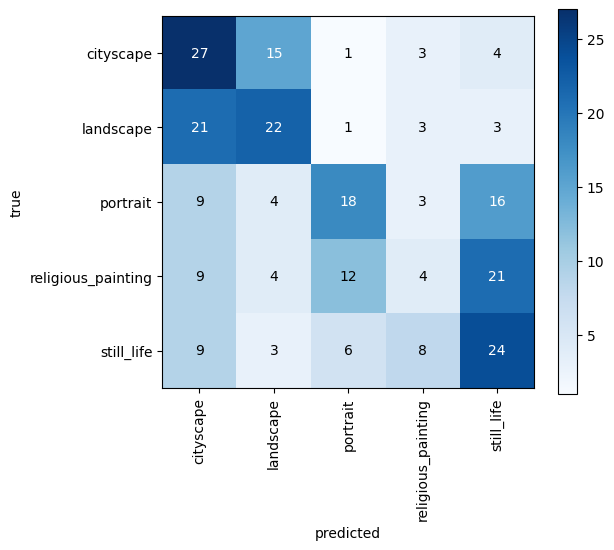

most frequent mistake: landscape predicted as cityscape (21 times)


In [10]:
model.eval()
with torch.no_grad():
    pred = model(X_test.to(device)).argmax(dim=1).cpu()   # predicted class of every test image

cm = confusion_matrix(y_test.numpy(), pred.numpy())
off = cm.copy()
np.fill_diagonal(off, 0)                                   # ignore the correct predictions
true_cls, pred_cls = np.unravel_index(off.argmax(), off.shape)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks(range(len(CLASSES)), CLASSES, rotation=90); plt.yticks(range(len(CLASSES)), CLASSES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.colorbar(); plt.show()
print(f"most frequent mistake: {CLASSES[true_cls]} predicted as {CLASSES[pred_cls]} ({cm[true_cls, pred_cls]} times)")

**What we see.** 0.38 on the test set, about twice the chance level (0.20). The training loss keeps going down
(0.78 after 10 epochs) while the validation loss stays around 1.5: the network fits its 1 000 training images much
better than new ones (6.3 million parameters; the curves and the diagnosis come in milestone m2).

The two outdoor genres are mixed up the most: 21 landscapes predicted as cityscapes and 15 cityscapes as landscapes
(sky at the top, a horizon, similar colours). Religious paintings are almost never recognised (4 out of 50), mostly
predicted as still lifes (21) or portraits (12). A dense layer sees 49 152 independent numbers: flattening throws away
the 2-D structure of the image (Session 5). A convolutional network pretrained on ImageNet is the next step
(milestone m3).